#Predicting Protein Content in Fast-Food Items
University coursework — Linear Regression

>This notebook explores fast-food nutritional data and builds ordinary least squares (OLS) regression models to predict protein content.

**Workflow**: data inspection → filtering → missing-value treatment → correlation analysis → predictor selection → train/test split → model fitting → diagnostics → multicollinearity assessment.

**Data requirement**: fastfood.csv must be available in the notebook's working directory. The dataset is not included in this repository.

**Attribution**: Adapted for a personal coursework portfolio from exercises in the Faculty of Organizational Sciences Artificial Intelligence course.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import shapiro


#1. Loading dataset and inspection

In [18]:
data = pd.read_csv('fastfood.csv', na_values=['NA'])
display(data.head())
print(data.info())

data.isna().sum()

# We see that the columns such as restaurant, item, cel_fat and protein are loaded as non numeric types.
# We will leave columes item and restaurant in this form because they are naturally numeric.
# Also we see the columns fiber, protein and calcium have NA values

,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,calcium
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60,7,2.0,0.0,95,1110,44,3.0,11,37,20.0
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410,45,17.0,1.5,130,1580,62,2.0,18,46,20.0
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600,67,27.0,3.0,220,1920,63,3.0,18,70,50.0
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280,31,10.0,0.5,155,1940,62,2.0,18,55,20.0
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410,45,12.0,0.5,120,1980,81,4.0,18,46,20.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   restaurant   515 non-null    object 
 1   item         515 non-null    object 
 2   calories     515 non-null    int64  
 3   cal_fat      515 non-null    object 
 4   total_fat    515 non-null    int64  
 5   sat_fat      515 non-null    float64
 6   trans_fat    515 non-null    float64
 7   cholesterol  515 non-null    int64  
 8   sodium       515 non-null    int64  
 9   total_carb   515 non-null    int64  
 10  fiber        503 non-null    float64
 11  sugar        515 non-null    int64  
 12  protein      514 non-null    object 
 13  calcium      305 non-null    float64
dtypes: float64(4), int64(6), object(4)
memory usage: 56.5+ KB
None


,0
restaurant,0
item,0
calories,0
cal_fat,0
total_fat,0
sat_fat,0
trans_fat,0
cholesterol,0
sodium,0
total_carb,0


#2. Filtering and cleaning the dataset

In [19]:
# Making a new dataset with items that have total fat count 125 or less
data_subset = data.loc[data['total_fat'] <= 125].copy()

print(f"Number of rows in data_subset: {len(data_subset)}")
print(f"Number of rows in original dateset: {len(data)}")



Number of rows in data_subset: 513
Number of rows in original dateset: 515


In [20]:
# Replacing placeholders that have missing values
special_missing = ['-', ' ', '']

# Checking to see wich colums have special characters in their values
print(data_subset.isin(['-', ' ', '']).sum())

# Replacing special characters
data_subset.replace(special_missing, np.nan, inplace=True)

print(data_subset.isin(['-', ' ', '']).sum())

# Turning cal_fat and protein columns into numeric type columns
data_subset['protein'] = pd.to_numeric(data_subset['protein'], errors='coerce')
data_subset['cal_fat'] = pd.to_numeric(data_subset['cal_fat'], errors='coerce')

# We are making a new subset with only numeric columns
data_numeric = data_subset.select_dtypes(include=['number']).copy()

print(data_numeric.columns)
print(data_numeric.info())

restaurant     3
item           0
calories       0
cal_fat        1
total_fat      0
sat_fat        0
trans_fat      0
cholesterol    0
sodium         0
total_carb     0
fiber          0
sugar          0
protein        1
calcium        0
dtype: int64
restaurant     0
item           0
calories       0
cal_fat        0
total_fat      0
sat_fat        0
trans_fat      0
cholesterol    0
sodium         0
total_carb     0
fiber          0
sugar          0
protein        0
calcium        0
dtype: int64
Index(['calories', 'cal_fat', 'total_fat', 'sat_fat', 'trans_fat',
       'cholesterol', 'sodium', 'total_carb', 'fiber', 'sugar', 'protein',
       'calcium'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
Index: 513 entries, 0 to 514
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   calories     513 non-null    int64  
 1   cal_fat      512 non-null    float64
 2   total_fat    513 non-null    int64  
 3   

In [21]:
# Checking to see wich numeric columns have missing values and the percentige of it so that we could make a decision if the missing values could be replaced or not
data_numeric.isna().sum()

print((data_numeric.isna().mean() * 100).round(2))

# We see that the column calcium has a lot of mising values and we are gonna delete it from the subset because we tolerate 20% of missing values in a column

data_numeric.drop(columns='calcium', inplace=True)

calories        0.00
cal_fat         0.19
total_fat       0.00
sat_fat         0.00
trans_fat       0.00
cholesterol     0.00
sodium          0.00
total_carb      0.00
fiber           2.34
sugar           0.00
protein         0.39
calcium        40.74
dtype: float64


In [22]:
# We are checking normal distribution for other columns that have missing values
cols_with_na = ['cal_fat', 'fiber', 'protein']

for col in cols_with_na:
    series = data_numeric[col].dropna()
    stat, p = shapiro(series)
    print(f"{col}: p = {p:.5f} → {'not normal' if p < 0.05 else 'normal'} distribution")

# Given that the columns don't have normal distribution, we will replace missing values with the median value of that column
for col in cols_with_na:
    median = data_numeric[col].median()
    data_numeric[col] = data_numeric[col].fillna(median)

data_numeric.isna().sum()


cal_fat: p = 0.00000 → not normal distribution
fiber: p = 0.00000 → not normal distribution
protein: p = 0.00000 → not normal distribution


,0
calories,0
cal_fat,0
total_fat,0
sat_fat,0
trans_fat,0
cholesterol,0
sodium,0
total_carb,0
fiber,0
sugar,0


#3. Exploring correlations

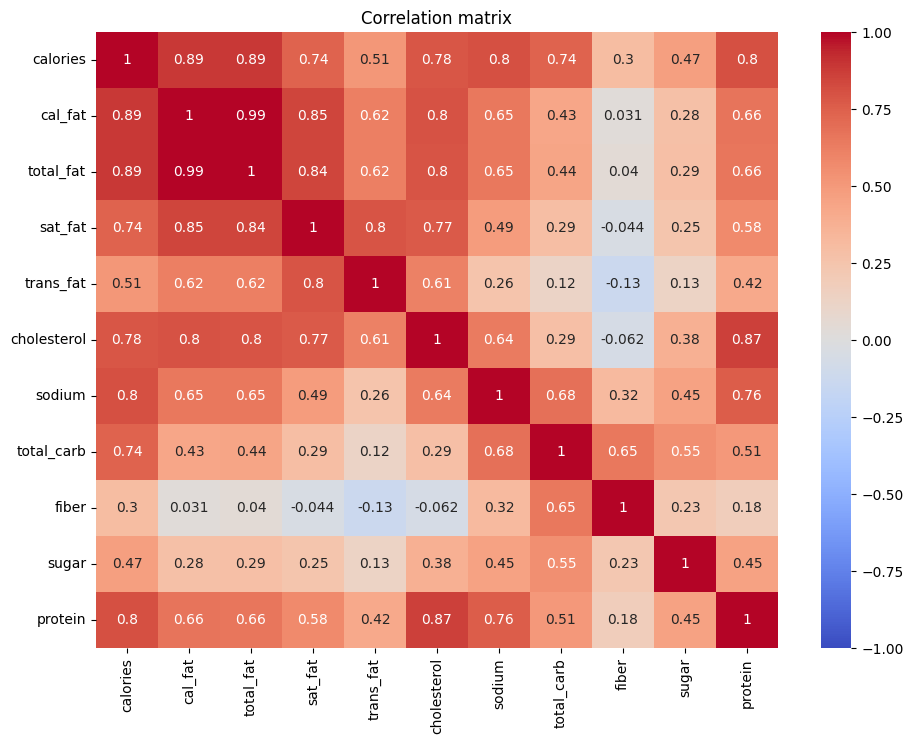

In [23]:
corr = data_numeric.corr(numeric_only=True).round(4)
plt.figure(figsize=(11,8))
sb.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.show()

#4. Selecting predictors

In [24]:
# In the correlation matrix we can see that there are 3 important columns (highest correlation) for predicting atrribute protein:
# 1) cholesterol - 0.87
# 2) calories - 0.8
# 3) sodium - 0.76

target = 'protein'
features = ['cholesterol', 'calories', 'sodium']


#5. Splitting data into train and test subsets

In [26]:
train_df, test_df = train_test_split(data_numeric, test_size=0.2, random_state=123, shuffle=True, stratify=pd.qcut(data_numeric['protein'],q=10,duplicates='drop'))

print(f"Number of rows in train set: {len(train_df)}")
print(f"Number of rows in test set: {len(test_df)}")


Number of rows in train set: 410
Number of rows in test set: 103


#6. Making a model

In [27]:
lm1 = smf.ols(f'{target} ~ ' + ' + '.join(features), data=train_df).fit()
print(lm1.summary())

                            OLS Regression Results                            
Dep. Variable:                protein   R-squared:                       0.806
Model:                            OLS   Adj. R-squared:                  0.804
Method:                 Least Squares   F-statistic:                     561.8
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          4.45e-144
Time:                        15:49:47   Log-Likelihood:                -1358.9
No. Observations:                 410   AIC:                             2726.
Df Residuals:                     406   BIC:                             2742.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       3.6004      0.758      4.752      

In [12]:
# Residuals represent the difference between the actual and predicted values of the target variable (protein).
# Ideally, they should be evenly distributed around zero.

# The median of the residuals is -0.702, meaning that half of the errors are smaller and half are larger than this value.

# The intercept is 3.6004.
# This means that when all independent variables are equal to zero, the expected protein value is approximately 2.51.

# Coefficients:
# - cholesterol: coefficient 0.1970 → an increase of 1 unit leads to an increase in protein of approximately 0.179.
# - calories:    coefficient 0.0057 → an increase of 1 unit leads to an increase in protein of approximately 0.0052.
# - sodium:      coefficient 0.0066 → an increase of 1 unit leads to an increase in protein of approximately 0.0067.

# Statistical significance:
# - cholesterol and sodium have p-values < 0.001 → highly significant predictors.
# - calories has p = 0.047 → also statistically significant (p < 0.05).

# R-squared is 0.806 → the model explains approximately 80.6% of the variability in the target variable.

# The F-statistic is high (561.8), and the p-value is close to zero → the model is statistically significant overall.

# Warning: The condition number is 3.47e+03 → multicollinearity may be present.
# Further investigation is recommended (e.g., using VIF values).


#7. Predictions on the test subset

In [28]:
y_true = test_df['protein']
X_test = test_df[['cholesterol', 'calories', 'sodium']]

y_pred = lm1.predict(X_test)

# Making DataFrame to compare the predictions with the real result of the model
results = pd.DataFrame({
    'Real': y_true.values,
    'Predicted': y_pred.round(2)
})

print(results.head(10))


     Real  Predicted
80   34.0      32.59
224  36.0      38.13
37   94.0      74.69
365  16.0      10.15
264  30.0      32.33
178  43.0      38.26
279  35.0      39.46
22   29.0      29.86
89   19.0      22.09
449   8.0      11.26


In [32]:
rss = ((y_pred - y_true)**2).sum()
tss = ((y_true.mean() - y_true)**2).sum()
r2 = 1-rss/tss
rmse = np.sqrt(rss/len(y_true))

print("rss = ", rss)
print("tss = ", tss)
print("r2 = ", r2)
print("rmse = ", rmse)

rss =  3733.691261308522
tss =  30054.718446601943
r2 =  0.8757702133213409
rmse =  6.020749930153383


In [33]:
# The Residual Sum of Squares (RSS) is 3733.69, representing the total squared
# difference between the actual and predicted protein values.

# The Total Sum of Squares (TSS) is 30054.72, representing the total variability
# of the actual protein values around their mean.

# The R-squared (R²) value is 0.8758, indicating that the model explains
# approximately 87.58% of the variability in protein content.
# This suggests a strong fit to the evaluated dataset.

# The Root Mean Squared Error (RMSE) is 6.02, meaning that the typical
# prediction error is approximately 6.02 units of protein content.
# RMSE gives greater weight to larger prediction errors.

# OVERALL CONCLUSION
# The regression model demonstrates strong predictive performance,
# explaining approximately 87.58% of the variability in protein content.
# However, the RMSE indicates that some prediction errors remain.
# Further evaluation of residuals and comparison with alternative models
# would help determine whether the model can be improved.

#8. Regression diagnostics

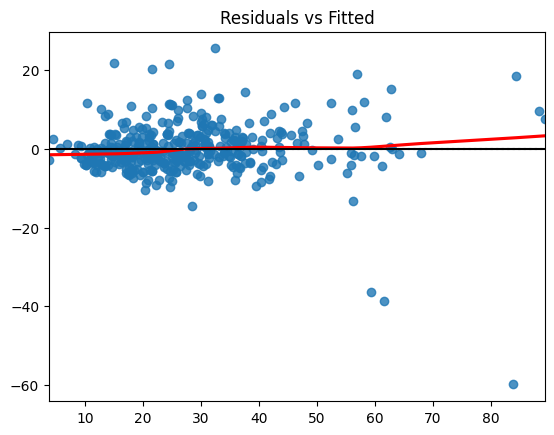

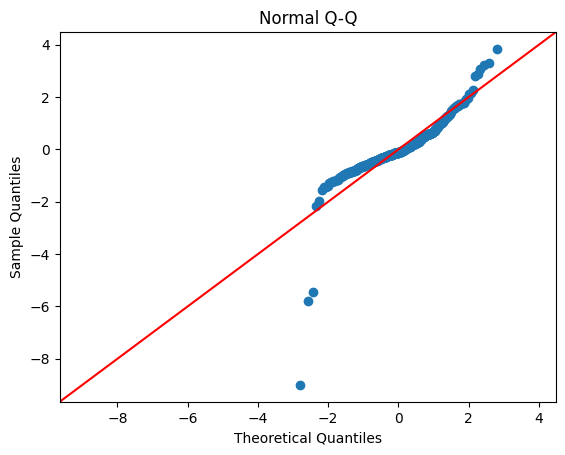

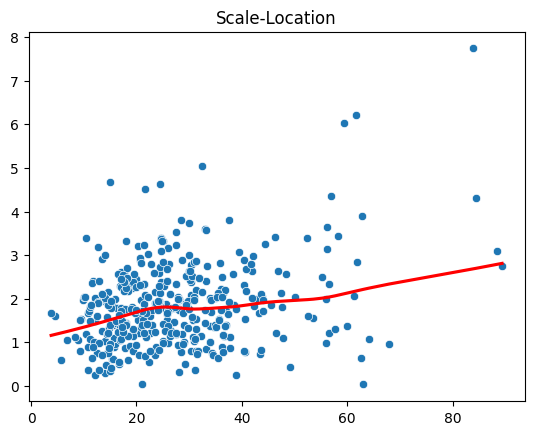

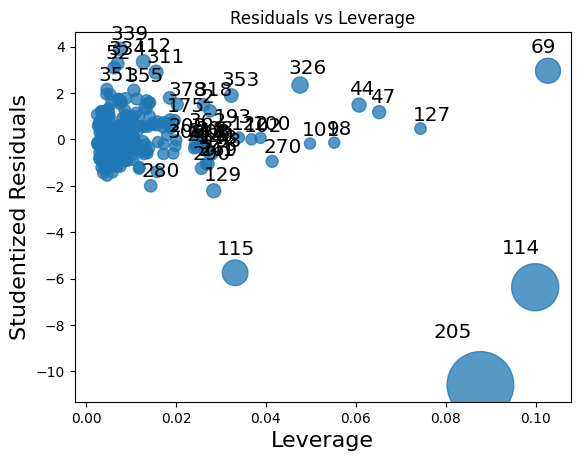

In [34]:
sb.residplot(x=lm1.fittedvalues, y=lm1.resid, lowess=True, line_kws={'color':'red'})
plt.axhline(0, color='black'); plt.title('Residuals vs Fitted'); plt.show()

sm.qqplot(lm1.resid, fit=True, line='45'); plt.title('Normal Q-Q'); plt.show()

sqrt_abs_resid = np.sqrt(np.abs(lm1.resid))
sb.scatterplot(x=lm1.fittedvalues, y=sqrt_abs_resid)
sb.regplot(x=lm1.fittedvalues, y=sqrt_abs_resid, scatter=False, lowess=True, line_kws={'color':'red'})
plt.title('Scale-Location'); plt.show()

sm.graphics.influence_plot(lm1, criterion='cooks'); plt.title('Residuals vs Leverage'); plt.show()

In [15]:
# REGRESSION DIAGNOSTICS – CONCLUSION

# 1. Residuals vs Fitted
# Most residuals are distributed around zero, and the trend line is relatively flat.
# This suggests that the linear relationship is reasonably appropriate.
# However, several outliers are present, including observations with large negative residuals.

# 2. Normal Q-Q Plot
# Most observations follow the theoretical reference line in the central region.
# However, significant deviations are visible in both tails of the distribution.
# This indicates that the residuals are not perfectly normally distributed,
# mainly due to extreme observations and potential outliers.

# 3. Scale-Location Plot
# The red trend line generally increases as fitted values increase.
# This suggests that the variance of residuals is not constant.
# Therefore, heteroscedasticity may be present in the regression model.

# 4. Residuals vs Leverage
# Most observations have relatively low leverage.
# However, several observations have high leverage and large standardized residuals.
# Observations 114 and 115 appear particularly influential.
# These observations should be investigated because they may affect model estimates.

# OVERALL CONCLUSION
# The regression model explains a substantial proportion of the variability
# in protein content (R-squared = 0.852).
# However, the diagnostic plots reveal several potential issues:
# deviations from residual normality, heteroscedasticity, and influential observations.
# Although the model demonstrates strong explanatory performance on the training data,
# some regression assumptions are not fully satisfied.
# Further investigation of outliers, influential observations, and model
# specification is recommended to improve the reliability of the results.

#9. Checking multicollinearity and fitting a reduced model

In [35]:
X = sm.add_constant(train_df[features])
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
print('√VIF first version:\n', np.sqrt(vif))

# Since the sqrt(VIF) value for the calories attribute is greater than 2, it can be concluded that multicollinearity is present, which may lead to unreliable coefficient estimates.
# A new model for predicting protein content should be created using the cholesterol and sodium attributes.
lm2 = smf.ols(f'{target} ~ cholesterol + sodium', data=train_df).fit()

X = sm.add_constant(train_df[['cholesterol', 'sodium']])
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
print('√VIF second version:\n', np.sqrt(vif))
# There is no more multicollinearity


√VIF first version:
 const          1.000000
cholesterol    1.627336
calories       2.102288
sodium         1.661183
dtype: float64
√VIF second version:
 const          1.000000
cholesterol    1.285878
sodium         1.285878
dtype: float64
